## January 2026 
In this file I will test the output of the new version of CosmoTherm FH. <br>
I will look at the anisotropic spectral distortions sourced by photon to dark photon conversion and compare it with a normal gaussian heating. <br>


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
import math
from scipy.interpolate import CubicSpline 

In [2]:
#===============================================================================================================
# Plotting setup
#===============================================================================================================

from my_plot import set_size
import seaborn as sns
width =  508.0
widthcol = 244
plt.rcParams['font.size']=12

colors1=sns.color_palette("rocket",4) #personal fav 
colors2=sns.color_palette("mako",4) #also nice
colors3 = plt.colormaps['Spectral'].resampled(4)

colors4 = ['#c3121e', '#0348a1',  '#027608', '#0193b0', '#9c5300', '#949c01', '#7104b5']
#            0sangre,   1neptune,  2pumpkin,  3clover,   4denim,    5cocoa,    6cumin,    7berry
colors5 = ['#027608',"#fca70b", '#7104b5']


#===============================================================================================================
# Function to format numbers in scientific notation for plots
#===============================================================================================================

f =  ScalarFormatter(useOffset=False, useMathText=True)
f.set_scientific(True)
f.set_powerlimits((0, 0))

def sci_notation(x):
    if x == 0:
        return "0"
    else:
        formatted = f"{x:.2e}"  # Converte in notazione scientifica
        coefficient, exponent = formatted.split('e')
        exponent = int(exponent)  # Converti l'esponente a intero
        return f"${coefficient} \\times 10^{{{exponent}}}$"  # Notazione LaTeX

#===============================================================================================================    
# Physical constants
#===============================================================================================================

K = 1.380649e-23 # J / K
vc = 299792458 # m / s
h_pl = 6.62607015e-34 # J*s
T_cmb = 2.726 # K
omegab_h2 = 0.0224

I0 =(2*K**3*T_cmb**3)/(vc**2*h_pl**2)*1e26 # in Jy / sr
print(I0/1e6, "MJy sr^-1")

#===============================================================================================================
# Normalised distortion spectral shapes
#===============================================================================================================

def nbb(x): return (1/(np.exp(x)-1)) # * I0
def G(x): return (x * np.exp(x) * nbb(x)**2 )   # intensity not occupation number /4.0 * I0
def Y(x): return x**3 * I0 * (G(x) * ( x * ( 2 * nbb(x) + 1 ) - 4 ) ) / 4.0
def M(x): return x**3 * I0 * (G(x) * ( 1.0 / 2.1923 - 1.0 / x ) ) * 1.401
def D(x): return x**3 * I0 * (G(x) * 1.6449 / (3*2.4041) - nbb(x) / x) / 0.5421 
    


270.2115654196308 MJy sr^-1


In [3]:
def extract_custom_state_from_files(folder_path, ell, pattern="custom_state_kv_001_yn_aniso_system-all_wG.dat_ymax15_lmax25_adiabatic.dat"):
    """Extract custom transfer function data from files in a folder """
    folder = Path(folder_path) / "batch" / "FH" 
    file_path = next(folder.glob(pattern))
    
    theta = [[] for _ in range(ell+1)]
    mu = [[] for _ in range(ell+1)]
    y = [[] for _ in range(ell+1)]
    z = []
    
    data = np.loadtxt(file_path, comments='#')  
    z.extend(data[:, 0])  # First column is redshift
    for i in range(ell+1):
        theta[i].extend(data[:, 1+i*(ell)])   # All theta values from column 1 and multiples of it
        print( " theta ", i, "comes from column ", 1+i*(ell))
        y[i].extend(data[:, 2+i*(ell)])       # All y values from column 2 and multiples of it
        print( " y ", i, "comes from column ", 2+i*(ell))
        mu[i].extend(data[:, 3+i*(ell)])  # All mu values from column 3 and multiples of it
        print( " mu ", i, "comes from column ", 3+i*(ell))
    
    return z, np.array(theta), np.array(y), np.array(mu)

In [4]:
def extract_state_scattering_basis(folder_path, ell, k):
    """Extract scattering basis transfer function data from files in a folder """
    folder = Path(folder_path) / "batch" / "FH" 
    file_path = []
    file_path2 = []
    for i in range(ell+1):
        file_path.append(next(folder.glob(f"full_state_kv_{k}_yn_aniso_system-all_wG.dat_ymax15_lmax100_adiabatic_scattering-basis_{i}.dat")))
        file_path2.append(next(folder.glob(f"full_state_kv_{k}_yn_aniso_system-all_wG.dat_ymax15_lmax100_adiabatic_computation-basis_{i}.dat")))
    
    theta = [[] for _ in range(ell+1)]
    mu = [[] for _ in range(ell+1)]
    y = [[] for _ in range(ell+1)]
    a = []
    
   
    for i in range(ell+1):
        data = np.loadtxt(file_path[i], comments='#') 
        data_theta = np.loadtxt(file_path2[i], comments='#')
        if i == 0:
            a.extend(data[:, 0])  # First column is redshift (only read once)

        theta[i].extend(data_theta[:, 1])   
        y[i].extend(data[:, 2])       
        mu[i].extend(data[:, 9])    
    
    return a, np.array(theta), np.array(y), np.array(mu)

In [6]:
ell = 2
kv_values = ["001", "002", "003","004", "005"]
theta = []
y = []
mu = []
a = []

for kv in kv_values:
    zt, th, yy, m = extract_state_scattering_basis(
        "../Data/dp-aniso-3/", ell,
        kv
    )
    theta.append(th)
    y.append(yy)
    mu.append(m)
    a.append(zt)

In [7]:
kv_values_Mpc = [1,0.1,0.01,0.001,0.0001]

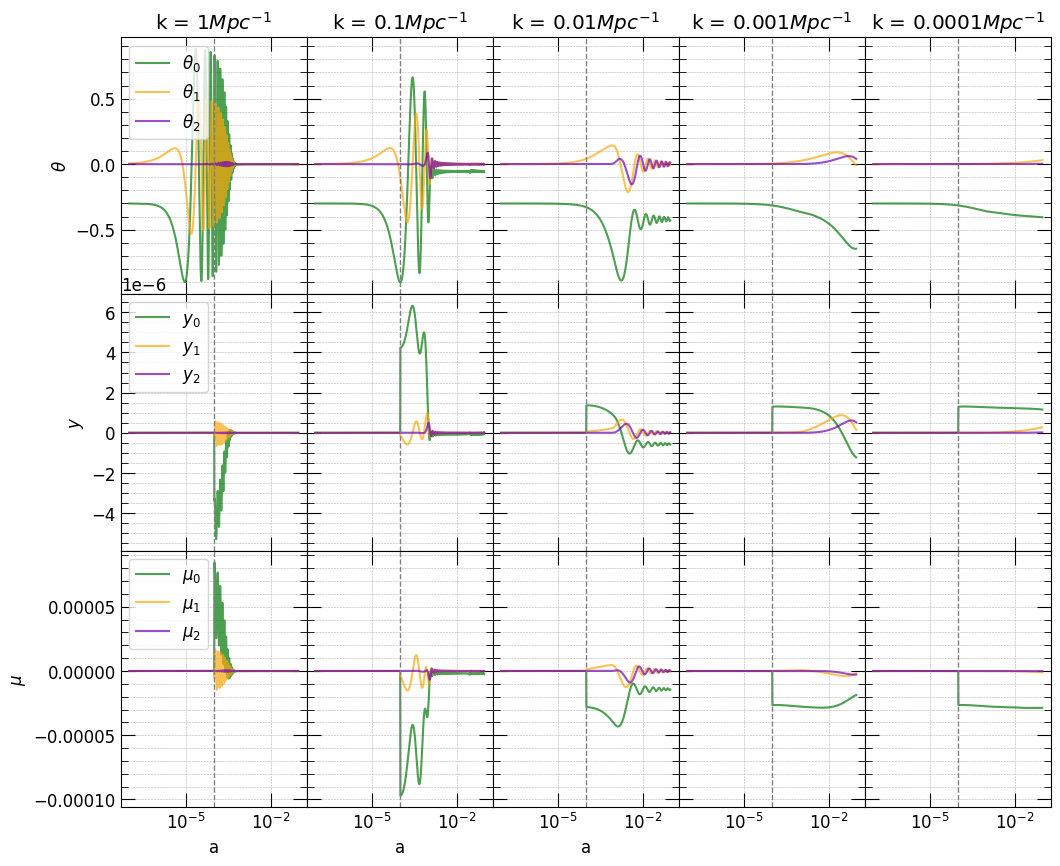

In [11]:
# Plot Analytical Spectra
fig, ax1 = plt.subplots(3, 5, figsize=(12, 10), sharey='row')
fig.subplots_adjust(hspace=0, wspace=0)

# Loop over columns (kv = 001, 002, 003) and rows (ell = 1, 2, 3)
for col in range(5):  # columns for different kv values
    for ell_idx in range(ell+1):  # ell multipoles 1, 2, 3
        ax1[0, col].plot(a[col], theta[col][ell_idx], label=f"$\\theta_{ell_idx}$", color=colors5[ell_idx], alpha=0.7, linestyle="-")
        ax1[1, col].plot(a[col], y[col][ell_idx], label=f"$y_{ell_idx}$", color=colors5[ell_idx], alpha=0.7, linestyle="-")
        ax1[2, col].plot(a[col], mu[col][ell_idx], label=f"$\\mu_{ell_idx}$", color=colors5[ell_idx], alpha=0.7, linestyle="-")
    
    ax1[0, col].set_xscale('log')
    ax1[1, col].set_xscale('log')
    ax1[2, col].set_xscale('log')
    ax1[0, col].set_title(f"k = {kv_values_Mpc[col]}" "$Mpc^{-1}$")

# Set labels for left column
ax1[0, 0].set_ylabel("$\\theta$")
ax1[1, 0].set_ylabel("$y$")
ax1[2, 0].set_ylabel("$\\mu$")

# Set x-labels for bottom row only
for col in range(3):
    ax1[2, col].set_xlabel("a")

# Remove x tick labels for top two rows
for row in range(2):
    for col in range(3):
        ax1[row, col].tick_params(labelbottom=False)

# Remove y tick labels for middle and right columns
for row in range(3):
    for col in range(1, 3):
        ax1[row, col].tick_params(labelleft=False)

# Apply formatting to all subplots
for ax in ax1.flat:
    ax.minorticks_on()
    ax.tick_params(direction='in', right=True, top=True)
    ax.tick_params(labelsize=12)
    ax.tick_params(direction='in', which='minor', length=5, bottom=True, top=True, left=True, right=True)
    ax.tick_params(direction='in', which='major', length=10, bottom=True, top=True, left=True, right=True)
    ax.grid(True, which='both', linestyle='--', linewidth=0.4)
    ax.axvline(x= 1 / (1+1e4), color='gray', linestyle='dashed', linewidth=1)

# Add legend to first column subplots
ax1[0, 0].legend(loc='upper left')
ax1[1, 0].legend(loc='upper left')
ax1[2, 0].legend(loc='upper left')

#plt.savefig('outputs/H0_evolution.pdf', dpi=300, bbox_inches="tight")
plt.show()